In [1]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

Heart Disease Prediction Using Gradient Boosting

Student Name: Vaishnodevi

Project Type: AI/ML Minor Project

Dataset: Heart Disease Dataset (heart.csv)

Algorithm: Gradient Boosting Classifier

Problem Statement

To develop a machine learning model that predicts the presence of heart disease using patient health-related attributes.

Objectives

1. Understand and analyze the heart disease dataset.
2. Perform data cleaning and preprocessing.
3. Explore the dataset using visualizations.
4. Build a Gradient Boosting classification model.
5. Evaluate the model using suitable performance metrics.

In [2]:
#upload and load the datset
from google.colab import files
uploaded = files.upload()

Saving heart.csv to heart (1).csv


In [3]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
#checks the dataset size
df.shape

(303, 14)

In [5]:
#dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [6]:
#statistical description
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [7]:
#check missing values
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [8]:
#check duplicate values
df.duplicated().sum()

np.int64(1)

In [9]:
#remove duplicate values
df = df.drop_duplicates()
print("Shape after removing duplicates:",df.shape)

Shape after removing duplicates: (302, 14)


In [10]:
#verifying duplicates are removed or not
df.duplicated().sum()

np.int64(0)

In [11]:
#analyze target values
df['target'].value_counts()

,count
target,
1,164
0,138


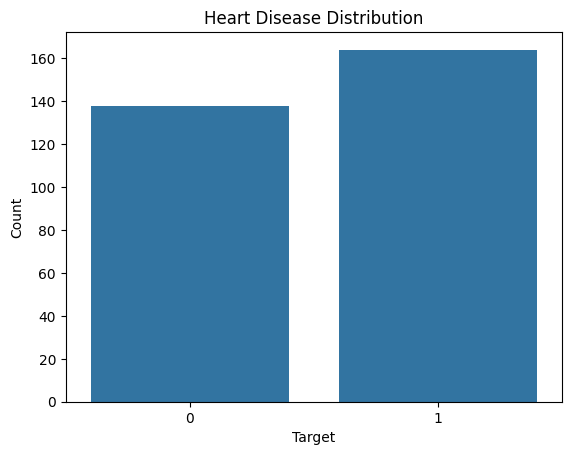

In [12]:
#visualize target distribution
sns.countplot(x='target',data=df)

plt.title('Heart Disease Distribution')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()


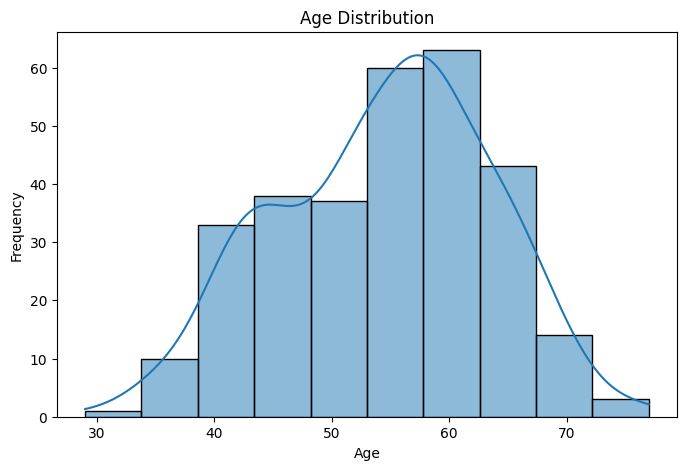

In [13]:
#age distribution
plt.figure(figsize=(8,5))
sns.histplot(df['age'],bins=10,kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

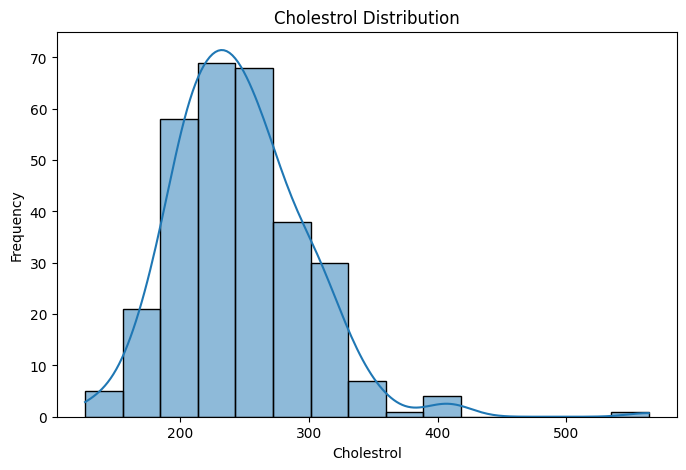

In [14]:
#cholestrol distribution
plt.figure(figsize=(8,5))
sns.histplot(df['chol'],bins=15,kde=True)

plt.title('Cholestrol Distribution')
plt.xlabel('Cholestrol')
plt.ylabel('Frequency')

plt.show()

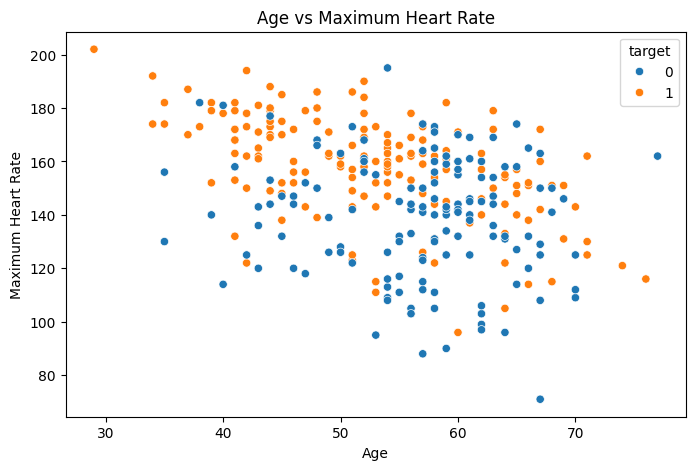

In [15]:
#age vs maximum heart rate
plt.figure(figsize=(8,5))
sns.scatterplot(x='age',y='thalach', hue='target',data=df)

plt.title('Age vs Maximum Heart Rate')
plt.xlabel('Age')
plt.ylabel('Maximum Heart Rate')

plt.show()

In [16]:
#seprate features and target
X = df.drop('target',axis=1)
y = df['target']

print('Features shape:',X.shape)
print('Target shape:',y.shape)


Features shape: (302, 13)
Target shape: (302,)


In [17]:
#split the dataset
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

Training data: (241, 13)
Testing data: (61, 13)


In [18]:
#train gradient boosting model
from sklearn.ensemble import GradientBoostingClassifier
model = GradientBoostingClassifier(random_state=42)
model.fit(X_train,y_train)
print("Model training completed")

Model training completed


In [19]:
#make predictions
y_pred = model.predict(X_test)
print(y_pred)

[0 0 1 0 1 1 0 0 0 0 1 0 1 0 1 1 1 0 0 0 1 0 1 1 1 1 0 1 0 1 0 0 0 0 1 0 1
 1 1 1 1 1 1 1 0 0 1 1 0 0 0 0 1 1 0 0 0 1 0 0 0]


In [20]:
#calculate model accuracy
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)
print("Model Accuracy:",accuracy * 100,"%")

Model Accuracy: 85.24590163934425 %


In [21]:
#classification report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.81      0.90      0.85        29
           1       0.90      0.81      0.85        32

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.86      0.85      0.85        61



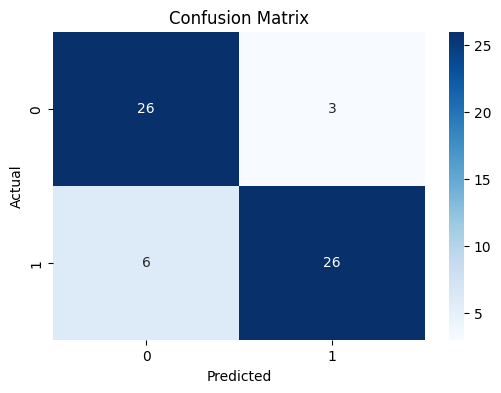

In [22]:
#confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [23]:
#compare actual and predicted values
result = pd.DataFrame({'Actual':y_test.values,'Predicted':y_pred})
result.head(10)

,Actual,Predicted
0,0,0
1,0,0
2,1,1
3,0,0
4,1,1
5,1,1
6,1,0
7,0,0
8,0,0
9,1,0


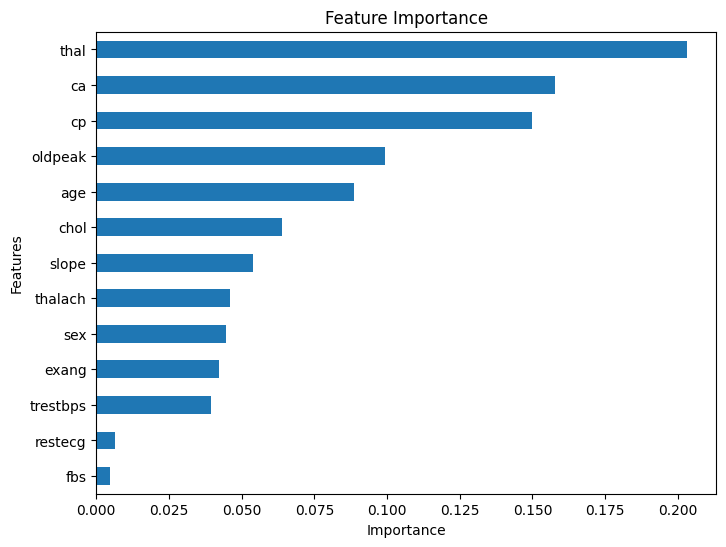

In [24]:
#feature importance
importance = pd.Series(model.feature_importances_,index=X.columns)
importance.sort_values().plot(kind='barh',figsize=(8,6))

plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

# Conclusion
Conclusion

In this project, we developed a Heart Disease Prediction model using the Gradient Boosting Classification algorithm.

We used the heart.csv dataset from Kaggle, performed data cleaning, explored the dataset and created visualizations.

After training and testing the model, we achieved an accuracy of 85.25%.

The project helped us understand data preprocessing, exploratory data analysis, machine learning and model evaluation.

Future Scope: The model can be improved using more data, feature selection and hyperparameter tuning.